# F.E. Walter: prepare a five-year operation comparison

## Goal

Follow the current 2021–2025 route from frozen hydrology inputs to one completed
Rule-based baseline and two prepared LLM methods. The notebook reads committed
files, checks the offline preparation, and displays saved figures. It does not
download data, recompute hydrology, advance reservoir state, or call a model.

The older [main notebook](main.ipynb) remains the historical 2016 configuration
walkthrough. Its saved LLM trajectories predate the daily seasonal context and
are not five-year results.

Read this lesson in order:

1. [Open the prepared experiment](#1-open-the-prepared-experiment)
2. [Trace the shared physical case](#2-trace-the-shared-physical-case)
3. [Read the Rule-based comparator](#3-read-the-rule-based-comparator)
4. [Switch to either LLM method](#4-switch-to-either-llm-method)
5. [Run the offline preflight](#5-run-the-offline-preflight)
6. [Inspect saved baseline evidence](#6-inspect-saved-baseline-evidence)

## Setup

Complete [installation](../docs/GETTING_STARTED.md), open
`tutorials/operation.ipynb` from the repository clone, select that environment,
and run cells in order. All paths below resolve from the repository root.

In [1]:
from pathlib import Path
import html, json, re, sys

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "src/llm_reservoir_agent").is_dir())
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT))

import pandas as pd
from IPython.display import Image

class ReadableText:
    def __init__(self, title, text, expanded=True):
        self.title, self.text, self.expanded = title, text, expanded
    def _repr_markdown_(self):
        fence = "`" * max(4, 1 + max((len(run) for run in re.findall(r"`+", self.text)), default=0))
        return f"#### {self.title}\n\n{fence}text\n{self.text}\n{fence}"
    def _repr_html_(self):
        content = f'<pre class="config-source">{html.escape(self.text)}</pre>'
        if self.expanded:
            return f'<h4>{html.escape(self.title)}</h4>{content}'
        return f'<details><summary>{html.escape(self.title)} — complete text</summary>{content}</details>'

def show_file(relative_path, title=None, *, expanded=True):
    path = ROOT / relative_path
    display(ReadableText(title or path.name, path.read_text(encoding="utf-8"), expanded))

operation = ROOT / "examples/fe_walter/operation"
pd.set_option("display.max_colwidth", 120)

## 1. Open the prepared experiment

Open [experiment.yaml](../examples/fe_walter/operation/experiment.yaml) in the
[case folder](../examples/fe_walter/operation/). The operation entry uses
`llm-reservoir-experiment.v2`, which loads the frozen
network and daily local-inflow CSV. The complete maintained YAML is shown below;
comments are part of the teaching source. The dates are inclusive, so 2021-01-01
through 2025-12-31 contains 1,826 operation decisions.

In [2]:
show_file(
    "examples/fe_walter/operation/experiment.yaml",
    "Complete Rule-based five-year experiment YAML",
)

#### Complete Rule-based five-year experiment YAML

````text
# Prepared daily operation: read frozen inflows; no hydrology is recomputed.
schema_version: llm-reservoir-experiment.v2  # Settings format, separate from package version.
run_id: fe-walter-2021-2025-rule         # Unique label for this method.
case: case.json                             # Shared reservoir and downstream network.
output: ../../../runs/fe-walter-2021-2025-rule  # New directory when eventually run.
start_date: '2021-01-01'                    # First daily decision (included).
end_date: '2025-12-31'                      # Last daily decision (included); 1826 days.
max_calls: 0  # 0 for rules; null leaves per-decision retry limits in force.
agents:
  file: agents.rule.yaml
auditors:
  file: ../coupled/auditors.yaml
extensions:
  seeded_hanasaki: __init__.py

````

| Field | Purpose | Required value for this lesson |
|---|---|---|
| `schema_version` | Select the prepared-operation settings contract. | `llm-reservoir-experiment.v2` |
| `case` | Load the shared reservoir, routed network, and frozen inflow source. | `case.json` |
| `start_date`, `end_date` | Bound the daily operation period. | 2021-01-01 through 2025-12-31 |
| `agents.file` | Select one decision method while retaining the same physical case. | `agents.rule.yaml` here |
| `extensions` | Register the case-specific seeded Hanasaki adapter. | `__init__.py` |

## 2. Trace the shared physical case

All three methods begin at **4,287,715.370246947 m³** on 2021-01-01 and use the
same prepared local inflows. The coupled hydrology stage already simulated
1989–2025 upstream and lateral runoff and routed it to the operation boundaries.
The operation lesson therefore reads `inflows.csv`; it does not rerun that stage.

The channel queues start empty on 2021-01-01, so the first 21 days are excluded
from primary downstream scores. They remain in the daily files and figures.

In [3]:
show_file("examples/fe_walter/operation/case.json", "Complete shared physical case")
show_file("examples/fe_walter/operation/provenance.json", "Complete input provenance", expanded=False)

case = json.loads((operation / "case.json").read_text(encoding="utf-8"))
provenance = json.loads((operation / "provenance.json").read_text(encoding="utf-8"))
inflows = pd.read_csv(operation / "inflows.csv", dtype={"date": str, "node": str})
physical = case["network"]["reservoirs"]["FEWalter"]["physical"]
display(pd.DataFrame([
    {"item": "Operation dates", "value": inflows["date"].nunique(), "unit": "unique dates"},
    {"item": "Local inflow boundaries", "value": inflows["node"].nunique(), "unit": "nodes"},
    {"item": "Initial storage", "value": physical["initial_storage_m3"], "unit": "m³"},
    {"item": "Capacity", "value": physical["capacity_m3"], "unit": "m³"},
    {"item": "Primary routing exclusion", "value": provenance["warmup"]["routing_primary_excluded_days"], "unit": "days"},
]))

#### Complete shared physical case

````text
{
  "network": {
    "schema_version": "llm-reservoir-network.v1",
    "data_kind": "simulated_local_inflow",
    "start_date": "2021-01-01",
    "reservoirs": {
      "FEWalter": {
        "inflow_node": "FEW_INFLOW",
        "physical": {
          "reservoir_id": "fe_walter",
          "capacity_m3": 135532852.33895192,
          "dead_storage_m3": 49.3392742128,
          "initial_storage_m3": 4287715.370246947,
          "minimum_release_cms": 1.41584235,
          "maximum_release_cms": 283.16847,
          "dt_seconds": 86400.0
        }
      }
    },
    "connections": [
      {
        "source": "FEWalter",
        "target": "USGS01447800",
        "unit_hydrograph": [
          0.8500882043365533,
          0.1416778716970155,
          0.006724331365982942,
          0.0011659017837799405,
          0.00025677254339484,
          6.349998879003367e-05,
          1.683369711419418e-05,
          4.675230200018779e-06,
          1.3426085801323462e-06,
          3.9540877119673675e-07,
          1.1876839532151555e-07,
          3.62435193306861e-08,
          1.120483309759428e-08,
          3.5018714884414733e-09,
          1.1045872622376605e-09,
          3.5118932399860527e-10,
          1.1242735003845511e-10,
          3.620957157303762e-11,
          1.1724433018655043e-11,
          3.814340148084056e-12,
          1.2462567210105844e-12
        ]
      },
      {
        "source": "USGS01447800",
        "target": "USGS01449000",
        "unit_hydrograph": [
          0.8954255104005965,
          0.10457448959940353
        ]
      }
    ],
    "outlet": "USGS01449000",
    "junctions": [
      "USGS01447800"
    ]
  },
  "data_kind": "simulated_local_inflow",
  "live_readiness": {
    "ready": true,
    "notes": [
      "The short FEWalter-to-White Haven reach and FEW-L-01/02 local runoff retain transferred upper-watershed parameters.",
      "Lehighton C&V validates combined local runoff and routing under an observed White Haven boundary; individual tributaries are not separately validated."
    ],
    "validation_reference": "../downstream/outputs/hydrology_validation/summary.json"
  },
  "schema_version": "llm-reservoir-network-case.v1",
  "inflow_source": {
    "path": "inflows.csv",
    "sha256": "818b688230673992c5a00f868ccc34f054d400f4d83dc88ad7b62b3bcf4b4d50",
    "format": "daily-node-local-cms.v1"
  }
}

````

#### Complete input provenance

````text
{
  "schema_version": "fe-walter-operation-inputs.v1",
  "operation_period": [
    "2021-01-01",
    "2025-12-31"
  ],
  "days": 1826,
  "hydrology": {
    "period": [
      "1989-01-01",
      "2025-12-31"
    ],
    "days": 13514,
    "model": "GWLF runoff and Lohmann routing; accepted semi-distributed setup",
    "weather": "Saved Daymet precipitation and temperature; Hamon PET",
    "boundary_preparation_sha256": "e7db1afa546ec783ee0c67ca459940f9ce4217de8c3f6c2fce5df074a85843ea",
    "inflow_bindings": {
      "FEW_INFLOW": "Reservoir upstream watershed",
      "USGS01447800": "Incremental runoff below the reservoir to White Haven",
      "USGS01449000": "Incremental runoff between White Haven and Lehighton"
    },
    "lower_validation": {
      "summary": "../downstream/outputs/hydrology_validation/summary.json",
      "summary_sha256": "56abfd6b7d95cbe7934396bb73fe3874ff5923fa32675aebbd67b389633490f8",
      "source_model_sha256": "7129cb86faf3c3b59d3ef0b26fafbce3da10fea38a4252768653ba6b5598bd6e",
      "parameter_blocks": {
        "RainfallRunoff": {
          "FEW-DS-01": "79b66471f8be08ac1eb7a3936902921904982f25d94a1d5c299d580402442bcc",
          "FEW-DS-02": "dbf2c35305092412736e32343f598ce28294b4ede1dd2323ed5836e2ed57b01a",
          "FEW-DS-03": "4322dea445cb84bb690fbde73f9154e320ebdfb82c6ff0fff3ba9b584bbe213d",
          "FEW-DS-04": "8454906472e26b22646ae2f41b0b0c8fd75d1dc00f9e161fc265321b9ee53bad",
          "FEW-DS-05": "fe9e24c8187282580da337b6a1f81e980e13ac2fc3ea71690336ceb31eac06ee",
          "FEW-DS-06": "ffa6efbca072ef6f6b6bf8552655e4609f0e950fc0b9b7733d9b27de3c563cde",
          "FEW-DS-07": "5fbab31eed776be9ecdb4b65338cc39fbfd76c7fb04c6026641eb6e635f8851f",
          "FEW-DS-08": "5a72e73f06ea9c7e461b4d9512de0855f2d5fc3ef7e4c823ab2a5472dd1948cb",
          "FEW-DS-09": "bf80e31a513f3f3f15133049cb68c75f736f4b42ecbe8d4265f89685dda25d0d",
          "WHITE_HAVEN": "7c35f7aedf6503eea47d9def465e16985ba10543764c3c767e085143a70d1a0f",
          "LEHIGHTON": "7c35f7aedf6503eea47d9def465e16985ba10543764c3c767e085143a70d1a0f"
        },
        "Routing": {
          "WHITE_HAVEN": "44136fa355b3678a1146ad16f7e8649e94fb4fc21fe77e8310c060f61caaff8a",
          "LEHIGHTON": "27fa59f23e04abac4fa40a8326c7e8639561ef8e4a82535a233823829f646df1"
        }
      },
      "operation_channel_sha256": "fdc8d79becbf4a9b62bf53328397b96327e89668dde8464bb72dfaa90325d501",
      "scope": "1990\u20132010 calibration and 2011\u20132020 independent validation of the combined White Haven-to-Lehighton runoff and routing, using observed White Haven flow.",
      "remaining_assumptions": [
        "The short FEWalter-to-White Haven reach and FEW-L-01/02 local runoff retain transferred upper-watershed parameters.",
        "Lehighton C&V validates combined local runoff and routing under an observed White Haven boundary; individual tributaries are not separately validated."
      ],
      "native_routing_final_weight_max_difference_cms": 0.00021329184328067186
    }
  },
  "warmup": {
    "hydrology_start": "1989-01-01",
    "operation_start": "2021-01-01",
    "routing_primary_excluded_days": 21,
    "routing_state": "Common empty channel queues on January 1; first 21 days excluded from primary flow scores.",
    "reservoir_state": "Shared observed local-midnight storage; no state nudging during evaluation."
  },
  "methods": {
    "rule": "Saved complete 1826-day baseline, alpha=0.85",
    "llm_available": "Prepared, not executed",
    "llm_knowledge": "Prepared, not executed"
  },
  "readiness": {
    "engineering": "Offline source, dates, common network, model settings and frozen C&V lineage checked",
    "scientific_live_ready": true,
    "reason": "Selected lower runoff/routing model is unchanged from completed C&V; retain the explicitly scoped near-dam regionalization and individual-tributary limits. LLM execution was not requested."
  },
  "originals": {
    "case.json": {
      "sha256": 

,item,value,unit
0,Operation dates,1.826000e+03,unique dates
1,Local inflow boundaries,3.000000e+00,nodes
2,Initial storage,4.287715e+06,m³
3,Capacity,1.355329e+08,m³
4,Primary routing exclusion,2.100000e+01,days


Read the complete [physical case](../examples/fe_walter/operation/case.json)
and [inflow CSV](../examples/fe_walter/operation/inflows.csv). In the JSON,
`network.reservoirs.FEWalter.physical` contains the storage and release settings.
The last two rows below identify the inflow connection and downstream reaches.

| Field | Meaning | Unit |
|---|---|---|
| `capacity_m3` | Maximum modeled total storage at the 1,450 ft flood pool. | m³ |
| `dead_storage_m3` | Protected lower computational bound; current field value remains uncertain. | m³ |
| `initial_storage_m3` | Shared storage at local midnight on 2021-01-01. | m³ |
| `minimum_release_cms`, `maximum_release_cms` | Physical bounds on controlled release. | m³/s |
| `dt_seconds` | Fixed duration of an operation step. | seconds |
| `network.reservoirs.FEWalter.inflow_node` | Node supplying reservoir inflow, `FEW_INFLOW`. | ID |
| `network.connections` | Directed reaches and their daily routing weights. | Weights sum to 1 |

The **135,532,852.34 m³** capacity corresponds approximately to the
1,450 ft flood-control pool in the saved conversion. The 49.34 m³ inactive/dead
storage floor has not been independently confirmed. Reservoir evaporation and
seepage are zero in this fixed comparison.

The [hydrology settings](../examples/fe_walter/operation/hydrology/hydrology.yaml)
connect each native outlet to one local inflow node. The
[accepted native model](../examples/fe_walter/operation/hydrology/model.yaml) and
[weather file](../examples/fe_walter/operation/hydrology/forcing.csv.gz) are retained
for reproducibility. This lesson reuses their saved inflows.

## 3. Read the Rule-based comparator

The completed baseline uses the generic published Hanasaki flood-control
comparator with `alpha: 0.85` from [Hanasaki et al. (2006), Eq. 3](https://doi.org/10.1016/j.jhydrol.2005.11.011).
This fixed generic setting provides the comparison baseline.
Its first coefficient is seeded from the prior operating year: storage
**21,914,228.648262143 m³** on 2020-05-01 gives
**k = 0.19022285020658533**. Each later May 1 refresh uses that method's own
simulated beginning-of-day storage. Every method still shares the physical
2021-01-01 initial storage shown above.

In [4]:
show_file("examples/fe_walter/operation/agents.rule.yaml", "Complete Rule-based agent settings")
show_file("examples/fe_walter/operation/initialization.json", "Complete Rule-based initialization")
show_file("examples/fe_walter/operation/hydrology/hydrology.yaml", "Complete hydrology boundary settings")
show_file("examples/fe_walter/coupled/auditors.yaml", "Complete release auditor settings")

#### Complete Rule-based agent settings

````text
# Case adapter supplies the accepted prior operating-year coefficient.
fe_operator:                                   # Independent decision history.
  reservoir_id: FEWalter                       # Reservoir ID in case.json.
  type: rule_based                             # Deterministic Hanasaki rule.
  rule: seeded_hanasaki                        # Case adapter registered in experiment.yaml.
  rule_parameters:
    purpose: flood_control                     # Generic non-irrigation operating purpose.
    alpha: 0.85                                # Published generic comparator; fixed before evaluation.
    inflow_statistics_file: ../../../data/benchmark/fe_walter_statistics.json
    initialization_file: initialization.json   # Prior coefficient plus common physical start (m3).
  auditors: [release_limits]                   # Audit requested release; preserve failures.

````

#### Complete Rule-based initialization

````text
{
  "schema_version": "fe-walter-rule-initialization.v1",
  "simulation_start": "2021-01-01",
  "coefficient_date": "2020-05-01",
  "coefficient_storage_m3": 21914228.648262143,
  "coefficient": 0.19022285020658533,
  "physical_initial_storage_m3": 4287715.370246947,
  "alpha": 0.85,
  "capacity_m3": 135532852.33895192,
  "source": {
    "agency": "USACE",
    "series_id": "FEWalter.Stor.Inst.15Minutes.0.Rev-DCP",
    "time_zone": "America/New_York",
    "source_sha256": "d61df27da427623c101e061379c58710e522d246ffbadec4899cac5fa4144eb5",
    "source_field": "start_local_midnight_storage_acft",
    "storage_acft": 17766.154296875,
    "acft_to_m3": 1233.48183754752,
    "preliminary": true
  },
  "selection": "Prior operating-year start; no 2021-2025 observation used for the coefficient.",
  "physical_initial_state": "2021-01-01 local midnight; common to all three methods.",
  "later_refresh": "Each May 1 uses that method's simulated beginning-of-day storage."
}

````

#### Complete hydrology boundary settings

````text
model: model.yaml
forcing: forcing.csv.gz
zero_flow_nodes:
- __AGGREGATION_OUTLET__
- __LATERAL_OUTLET__
- WHITE_HAVEN
- LEHIGHTON
- __PREPARATION_COLLECTOR__
inflow_bindings:
  FEW_INFLOW:
    routed: __AGGREGATION_OUTLET__
  USGS01447800:
    routed: __LATERAL_OUTLET__
  USGS01449000:
    routed: LEHIGHTON

````

#### Complete release auditor settings

````text
# Audit layer. Agents select this reusable profile by the release_limits ID.
release_limits:
  type: release_bounds  # Report whether proposed release is within physical bounds (m3/s).
  version: '1'          # Auditor-rubric version, separate from package and YAML schema versions.

````

## 4. Switch to either LLM method

The two prepared alternatives reuse the actual complete agents, model profile,
system prompts, and optional operating-knowledge document. Their physical case,
dates, inflows, auditors, model settings, and output schema stay aligned. Their
method names are:

- **LLM without additional operating knowledge**
- **LLM with additional operating knowledge**

Neither five-year LLM method has been executed, so this section contains settings
only. The historical 2016 LLM curves must not be interpreted as 2021–2025 results.

In [5]:
for title, path in [
    ("Five-year entry: LLM without additional operating knowledge", "examples/fe_walter/operation/llm_available.yaml"),
    ("Five-year entry: LLM with additional operating knowledge", "examples/fe_walter/operation/llm_knowledge.yaml"),
    ("Complete agent: without additional operating knowledge", "examples/fe_walter/coupled/agents.llm_available.yaml"),
    ("Complete agent: with additional operating knowledge", "examples/fe_walter/coupled/agents.llm_knowledge.yaml"),
    ("Complete shared model settings", "examples/fe_walter/coupled/models.yaml"),
    ("Complete prompt: available information", "examples/fe_walter/prompts/available_information.txt"),
    ("Complete prompt: retrieved knowledge", "examples/fe_walter/prompts/retrieved_knowledge.txt"),
    ("Complete operating-knowledge document", "examples/fe_walter/knowledge/operating_rules.md"),
]:
    show_file(path, title, expanded=False)

#### Five-year entry: LLM without additional operating knowledge

````text
# Prepared daily operation: read frozen inflows; no hydrology is recomputed.
schema_version: llm-reservoir-experiment.v2  # Settings format, separate from package version.
run_id: fe-walter-2021-2025-llm-available         # Unique label for this method.
case: case.json                             # Shared reservoir and downstream network.
output: ../../../runs/fe-walter-2021-2025-llm-available  # New directory when eventually run.
start_date: '2021-01-01'                    # First daily decision (included).
end_date: '2025-12-31'                      # Last daily decision (included); 1826 days.
max_calls: null  # 0 for rules; null leaves per-decision retry limits in force.
agents:
  file: ../coupled/agents.llm_available.yaml
auditors:
  file: ../coupled/auditors.yaml
models:
  file: ../coupled/models.yaml  # Same model and generation settings for both LLM methods.
extensions:
  reference_v3_7: ../extensions/__init__.py

````

#### Five-year entry: LLM with additional operating knowledge

````text
# Prepared daily operation: read frozen inflows; no hydrology is recomputed.
schema_version: llm-reservoir-experiment.v2  # Settings format, separate from package version.
run_id: fe-walter-2021-2025-llm-knowledge         # Unique label for this method.
case: case.json                             # Shared reservoir and downstream network.
output: ../../../runs/fe-walter-2021-2025-llm-knowledge  # New directory when eventually run.
start_date: '2021-01-01'                    # First daily decision (included).
end_date: '2025-12-31'                      # Last daily decision (included); 1826 days.
max_calls: null  # 0 for rules; null leaves per-decision retry limits in force.
agents:
  file: ../coupled/agents.llm_knowledge.yaml
auditors:
  file: ../coupled/auditors.yaml
models:
  file: ../coupled/models.yaml  # Same model and generation settings for both LLM methods.
extensions:
  reference_v3_7: ../extensions/__init__.py

````

#### Complete agent: without additional operating knowledge

````text
# Agent layer for the available-information method.
fe_operator:                          # Decision-unit ID used in plans and traces.
  reservoir_id: FEWalter              # Controlled reservoir ID in reservoirs.json.
  type: llm                           # Provider-backed operating method.
  model_profile: reservoir_model      # Profile ID from models.yaml.
  customization:
    backend: reference_v3_7           # Registered backend ID from the entry's extensions.
    # The backend owns this reference recipe; the framework keeps it opaque.
    parameters:
      reference:
        profile: fe_walter            # Backend's FE Walter physical/operating profile.
        method: zeroshot              # Available-information method, without a DKP document.
        consultation_mode: daily      # One decision opportunity per operation day.
        response_validation: policy   # Validate replies with the backend policy contract.
        # Relative to this file.
        system_prompt: ../prompts/available_information.txt
        system_prompt_mode: custom    # Use the declared system-prompt file.
        # Daily study-defined pool window context.
        seasonal_criteria_file: ../seasonal_pool_criteria.json
        prompt_storage: false         # Do not include storage in the prompt representation.
        hide_availability_line: true  # Preserve the approved prompt variant.
        dkp_no_missing_inputs: true   # Omit missing-input text from retrieved guidance.
        zeroshot_knowledge: target    # Supply target-operation context, not a DKP file.
  # Auditor IDs refer to profiles in auditors.yaml.
  auditors:
  - release_limits

````

#### Complete agent: with additional operating knowledge

````text
# Agent layer for the domain-knowledge method.
fe_operator:                                  # Decision-unit ID used in plans and traces.
  reservoir_id: FEWalter                      # Controlled reservoir ID in reservoirs.json.
  type: llm                                   # Provider-backed operating method.
  model_profile: reservoir_model              # Profile ID from models.yaml.
  customization:
    backend: reference_v3_7                   # Registered backend ID from the entry's extensions.
    # The backend owns this reference recipe; the framework keeps it opaque.
    parameters:
      reference:
        profile: fe_walter                    # Backend's FE Walter physical/operating profile.
        method: dkp                           # Include the declared domain-knowledge package.
        consultation_mode: daily              # One decision opportunity per operation day.
        response_validation: policy           # Validate replies with the backend policy contract.
        # Relative to this file.
        system_prompt: ../prompts/retrieved_knowledge.txt
        system_prompt_mode: custom            # Use the declared system-prompt file.
        # Daily study-defined pool window context.
        seasonal_criteria_file: ../seasonal_pool_criteria.json
        dkp: ../knowledge/operating_rules.md  # Knowledge document, relative to this file.
        prompt_storage: false                 # Do not include storage in the prompt representation.
        hide_availability_line: true          # Preserve the approved prompt variant.
        dkp_no_missing_inputs: true           # Omit missing-input text from retrieved guidance.
        zeroshot_knowledge: target            # Backend compatibility setting for target context.
  # Auditor IDs refer to profiles in auditors.yaml.
  auditors:
  - release_limits

````

#### Complete shared model settings

````text
# Shared provider profile. Agents select it with model_profile: reservoir_model.
reservoir_model:                    # Reusable profile ID, separate from the provider's model name.
  provider: ollama                  # Local Ollama HTTP protocol.
  model: gemma4:12b                 # Required model tag; install it before a live run.
  base_url: http://localhost:11434  # Ollama server root; the loader adds /api/chat.
  temperature: 0.7                  # Dimensionless sampling control (0 to 2).
  max_tokens: 2048                  # Maximum generated tokens; sent to Ollama as num_predict.
  num_ctx: 16384                    # Ollama context-window size in tokens.
  think: false                      # Do not request Ollama's separate thinking output.
  keep_alive: 30m                   # How long Ollama keeps the model loaded after a request.
  seed: null                        # Use the provider default rather than a fixed integer seed.
  timeout_seconds: 120              # Timeout for each provider attempt, in seconds.
  api_key_env: null                 # No environment-variable credential for this local endpoint.
  max_attempts: 2                   # Total tries per decision, including the first try.
  retry_delay_seconds: 2            # Wait between retryable attempts, in seconds.

````

#### Complete prompt: available information

````text
You are the operator of a reservoir, making one release decision per day.

Reservoir information (public sources):
- Name: F.E. Walter Dam on the Lehigh River, Pennsylvania
- Location: Bear Creek Township, Luzerne County and Kidder Township, Carbon County, Pennsylvania
- Purpose: flood control, water storage, recreation
- Opened: 1961; operated by the U.S. Army Corps of Engineers
- Type: earth-fill embankment with rock shell, impounding the Lehigh River
- Dam height (foundation): 234 ft; length: 3,000 ft
- Spillway type: concrete
- Catchment area: 289 square miles
- Total capacity (publicly reported): 110,700 acre-feet
- Operation target: Your goal is to keep the water level within the designated seasonal pool levels. From November 1 through March 14, keep the pool near the conservation pool at 1300.0 ft N.G.V.D., within 1297.0 to 1303.0 ft. From March 15 through May 9, keep the pool between 1300.0 and 1370.0 ft and, when hydrologic conditions allow, fill toward 1370.0 ft by May 10. From May 10 through October 14, keep the pool at or below 1370.0 ft. From October 15 through October 31, keep the pool between 1300.0 and 1370.0 ft and lower it toward 1300.0 ft by November 1.

Each day you will receive the current date, mean inflow,
water level at the beginning of the interval, and the previous one or two
simulated release decisions.
Flows are also stated as volumes in cubic feet over their interval, the
unit of the water balance. Decide the interval's mean release
in cfs, consistent with the reservoir's purpose. You have no operating
manual; use general reservoir-operation principles.

Physical water balance (not an operating rule):
- storage_change_cubic_feet = (inflow_cfs - release_cfs) * 86,400 * interval_days.
- A release below inflow increases storage; a release equal to inflow
  leaves storage approximately unchanged; a release above inflow decreases
  storage. Passing inflow cannot refill a reservoir below its target.

Constraints you must respect:
- Do not plan to release more water than is available (storage + inflow).
- Avoid letting storage exceed capacity (uncontrolled spill).
- Avoid abrupt interval-to-interval release changes unless conditions require them.

Respond only with JSON, with the fields in this order:
  applicable_target_ft (the operation-target water level for this interval),
  pool_position (below_target | at_target | above_target),
  intended_storage_direction (increase | hold | decrease),
  release_relation_to_inflow (below_inflow | equal_to_inflow | above_inflow),
  reasoning (1-2 sentences), release_cfs (number).
Decide the first four, then write the reasoning, then choose release_cfs.
Make release_cfs consistent with the four fields and with your reasoning.
````

#### Complete prompt: retrieved knowledge

````text
You are the water control manager operating F.E. Walter Dam on the Lehigh River, Pennsylvania,
making one release decision per day.

Reservoir information (public sources):
- Name: F.E. Walter Dam on the Lehigh River, Pennsylvania
- Location: Bear Creek Township, Luzerne County and Kidder Township, Carbon County, Pennsylvania
- Purpose: flood control, water storage, recreation
- Opened: 1961; operated by the U.S. Army Corps of Engineers
- Type: earth-fill embankment with rock shell, impounding the Lehigh River
- Dam height (foundation): 234 ft; length: 3,000 ft
- Spillway type: concrete
- Catchment area: 289 square miles
- Total capacity (publicly reported): 110,700 acre-feet
- Operation target: Your goal is to keep the water level within the designated seasonal pool levels. From November 1 through March 14, keep the pool near the conservation pool at 1300.0 ft N.G.V.D., within 1297.0 to 1303.0 ft. From March 15 through May 9, keep the pool between 1300.0 and 1370.0 ft and, when hydrologic conditions allow, fill toward 1370.0 ft by May 10. From May 10 through October 14, keep the pool at or below 1370.0 ft. From October 15 through October 31, keep the pool between 1300.0 and 1370.0 ft and lower it toward 1300.0 ft by November 1.

From the reservoir's water control manual:
- Storage at spillway crest (el. 1450.0 ft): 109,878 acre-feet
- Maximum allowable release: 10,000 cfs
- Minimum required release: 50 cfs

Your operating knowledge comes from the reservoir's Decision
Knowledge Package (DKP), extracted from the project's official
water control manual. Each day, the sections of the DKP most
relevant to the current conditions are retrieved and provided to
you together with the system state. Base your decision on those
retrieved DKP excerpts: apply their operating zones, decision
rules, release constraints, rating tables, and seasonal guidance.
This model represents the reservoir only: storage, inflow and release.
Apply the storage, inflow, seasonal and release-limit rules.
Do not invent an observation or rule.

How to apply the DKP in this simulation:
- Storage-to-elevation conversion is physical preprocessing and the current
  pool elevation may be supplied. Apply the shared operation target stated
  in the reservoir information; do not derive a different target from the DKP.
- Compare the current pool with that target yourself; no precomputed
  above-target or below-target interpretation is supplied.
- Gate-position rate limits are not discharge-rate limits. Do not convert
  them to cfs per hour without the required gate-rating information.
- Exhibit D's numerical recreation calendar is explicitly specific to 2014.
  In every other year, apply only the structural recreation constraints
  stated by the DKP and identify the annual calendar as unavailable; do not
  transfer the 2014 weekday, weekend, event-date, or numeric release schedule.
- No recommended release, target-tracking controller output, or precomputed
  above/below-target label is supplied. Select the release independently
  from the retrieved DKP rules and the raw state values.
- If the DKP does not provide a unique numeric release for the available
  inputs, do not invent an official formula. Choose the most defensible
  action allowed by the retrieved rules and explain it in the reasoning.
- No external reduced-domain release rule is supplied in this run.
- Use store_toward_target or draw_toward_target only when the selected
  release actually changes storage in that direction. Use pass_inflow only
  when the selected release is approximately equal to inflow.
- During seasonal refill, report store_toward_target; during seasonal
  drawdown, report draw_toward_target. Reserve recreation_plan for an
  applicable dated recreation-release instruction whose calendar is known.

Physical water balance (not an operating rule):
- storage_change_cubic_feet = (inflow_cfs - release_cfs) * 86,400 * interval_days.
- A release 

#### Complete operating-knowledge document

````text
# Decision Knowledge Package (DKP)
## Francis E. Walter Dam and Reservoir — Lehigh River, Lehigh River Basin, PA

> **DKP definition.** A Decision Knowledge Package is the discrete representational unit produced for a single decision-maker, encoding either deterministic-control logic (rules with variables) or distributional-behavioral patterns, together with a fallback policy for conditions its source material does not cover.

> **Revision note (2026-10-07) - reservoir-only model.** In `R-PLAN` only, the downstream control-gage thresholds, the gage-triggered Plan C and the sentence on downstream stage trends were removed, because the simulation supplies no downstream gage data; a pool between the seasonal target and 1450.0 ft is Plan B. Nothing else in this file is changed. The unedited file is kept as `DKP_FEWalter_Dam_v1.2_original.md`.

> **Version notice.** `DKP-FEWALTER-v1.2`. **Prescriptive source replaced.** Layer 2 is rebuilt from scratch against the governing *Water Control Manual (Revised), Francis E. Walter Dam and Reservoir* — USACE Philadelphia District, October 1961, revised October 1994, **revised September 2014** (redacted public edition, Chapters 1–9 + Pertinent Data). HEC PR-73 is **demoted from prescriptive to evidentiary**; no Layer 2 rule in this version cites PR-73. Walter now joins Prompton and Beltzville as a **single-prescriptive-source gold-standard DKP**.
>
> **Three substantive corrections to v1.0.** (1) v1.0's central characterization — a discretionary, case-by-case "deviation regime" (`FC_Ops_Dev`) for summer recreation pool — is **obsolete**. The 2014 WCM institutionalizes the seasonal raise to elevation 1370 as the *normal operational rule curve* (§7-01), not a deviation. (2) v1.0's downstream control stages (Lehighton 9.7 / Walnutport 6.3 / Bethlehem 9.9 ft) **do not exist in the WCM**; Table 7-2 prescribes a two-tier flood-stage / action-stage structure at five stations. The value 6.3 ft appears in the WCM only as an event-specific figure inside the August 1955 *routing narrative* (§8-02,d,2) — an evidentiary number promoted to a standing rule. (3) v1.0's rate-of-change rule was stated in the **wrong physical domain**: the WCM prescribes gate-position criteria (feet per 10 minutes), not a 500 cfs/hr discharge constraint. This is the **second independent instance** of the same domain-translation defect already logged at Beltzville, which makes it a systematic RT1 finding rather than a one-off.
>
> **v1.2 (2026-08-07) — TAB-A partially supplied; the DKP is now executable.** Table 7-1 Parts A and B, Table 7-3, Table 8-1 and Table 8-2 were added. The Maximum, Minimum and Water Quality Release Schedules close the v1.1 blocking gap: **release magnitude under every Schedule Plan is now computable.** Table 7-3 at 1-ft resolution with a day-second-feet column makes storage accounting and `R-INFLOW` executable. Table 8-1 adds a **53-year annual maximum series (WY1961–2013)** and Table 8-2 a five-event natural-vs-regulated record. Two new prescriptive rules appear (`R-TEMP`, `R-FILLING`) and eight new source defects are logged, including a precisely diagnosable off-by-one-foot error in Table 8-1's flood-storage denominator (Provenance 3(t)). Still absent: Tables 8-3 to 8-11 (station ratings), all Plates, Exhibits A–D.

---

## Layer 1 — Identity and System Metadata

| # | Field | Value |
|---|---|---|
| 1.1 | **DKP ID** | `DKP-FEWALTER-v1.2` (full tier) |
| 1.2 | **Decision type** | `deterministic-control` — plan-selecting (Schedule Plans A–D) with a seasonal rule curve; **jointly constrained** with Beltzville Lake |
| 1.3 | **Decision-maker represented** | Water Control Personnel, Northern Area Office, Operations Division, USACE Philadelphia District (CENAP); dam operators execute and assume regulation authority on loss of communications (WCM §5-08a, §7-04, §9-01,a,5) |
| 1.4 | **Decision output** | Gate setting on three flood-control service gates an

## 5. Run the offline preflight

`check_preparation()` verifies hashes, complete dates, finite nonnegative inflows,
the common physical case, separate future output paths, shared model settings,
saved result coverage, and the distinction between engineering and scientific
readiness. It loads settings for inspection only.

In [6]:
from examples.fe_walter.operation.preflight import check_preparation

readiness = check_preparation()
display(ReadableText("Offline preparation report", json.dumps(readiness, indent=2)))
display(pd.DataFrame(readiness["methods"]))

#### Offline preparation report

````text
{
  "engineering_ready": true,
  "live_ready": true,
  "scientific_limitations": [
    "The short FEWalter-to-White Haven reach and FEW-L-01/02 local runoff retain transferred upper-watershed parameters.",
    "Lehighton C&V validates combined local runoff and routing under an observed White Haven boundary; individual tributaries are not separately validated."
  ],
  "hydrology_validation": {
    "status": "complete",
    "selected_model": "seed-314159",
    "calibration": {
      "start": "1990-01-01",
      "end": "2010-12-31",
      "paired_days": 7670,
      "missing_days": 0,
      "excluded_days": 0,
      "mae_cms": 7.192977784934415,
      "rmse_cms": 13.45099231164119,
      "bias_cms": 0.710171430591028,
      "relative_volume_bias": 0.018692161006614916,
      "nse": 0.8772161826410154,
      "kge": 0.9350456214268003,
      "kge_method": "2009",
      "kge_components": {
        "correlation": 0.9383154397632153,
        "variability_ratio": 0.9919570253557651,
        "mean_ratio": 1.018692161006615
      },
      "undefined_metrics": {}
    },
    "validation": {
      "start": "2011-01-01",
      "end": "2020-12-31",
      "paired_days": 3653,
      "missing_days": 0,
      "excluded_days": 0,
      "mae_cms": 7.506741377480015,
      "rmse_cms": 13.623732267201781,
      "bias_cms": 1.164395851322823,
      "relative_volume_bias": 0.02986653581915593,
      "nse": 0.8753885739887544,
      "kge": 0.8691405712969543,
      "kge_method": "2009",
      "kge_components": {
        "correlation": 0.9373531967119766,
        "variability_ratio": 0.8890605653681151,
        "mean_ratio": 1.0298665358191559
      },
      "undefined_metrics": {}
    },
    "scope": "1990\u20132010 calibration and 2011\u20132020 independent validation of the combined White Haven-to-Lehighton runoff and routing, using observed White Haven flow.",
    "remaining_assumptions": [
      "The short FEWalter-to-White Haven reach and FEW-L-01/02 local runoff retain transferred upper-watershed parameters.",
      "Lehighton C&V validates combined local runoff and routing under an observed White Haven boundary; individual tributaries are not separately validated."
    ]
  },
  "period": [
    "2021-01-01",
    "2025-12-31"
  ],
  "days": 1826,
  "weather_units": 18,
  "weather_days_per_unit": 13514,
  "initial_storage_m3": 4287715.370246947,
  "routing_warmup_excluded_days": 21,
  "methods": [
    {
      "settings": "experiment.yaml",
      "days": 1826,
      "planned_decisions": 1826,
      "planned_llm_calls": 0,
      "output": "runs/fe-walter-2021-2025-rule"
    },
    {
      "settings": "llm_available.yaml",
      "days": 1826,
      "planned_decisions": 1826,
      "planned_llm_calls": 1826,
      "output": "runs/fe-walter-2021-2025-llm-available"
    },
    {
      "settings": "llm_knowledge.yaml",
      "days": 1826,
      "planned_decisions": 1826,
      "planned_llm_calls": 1826,
      "output": "runs/fe-walter-2021-2025-llm-knowledge"
    }
  ],
  "saved_results": {
    "rule": "complete",
    "llm_available": "not executed",
    "llm_knowledge": "not executed"
  },
  "expected_model_digest": "4eb23ef187e2c5462566d6a1d3bbbc2f1346d0b4327cbb66d58fffbcc9b2b05c",
  "model_identity_check": "Ollama was not contacted; verify the installed digest before a future live run.",
  "execution": "Offline inspection only; no hydrology, reservoir operation or provider run."
}
````

,settings,days,planned_decisions,planned_llm_calls,output
0,experiment.yaml,1826,1826,0,runs/fe-walter-2021-2025-rule
1,llm_available.yaml,1826,1826,1826,runs/fe-walter-2021-2025-llm-available
2,llm_knowledge.yaml,1826,1826,1826,runs/fe-walter-2021-2025-llm-knowledge


The lower hydrology has completed C&V: calibration uses 1990–2010,
and independent validation uses 2011–2020. The five-year model retains the selected
`seed-314159` runoff and routing parameters. Validation KGE is 0.869 and NSE is
0.875 under an observed White Haven boundary. The preflight checks this lineage
alongside the shared inputs and reports `live_ready: true`.

The short dam-to-White Haven reach and its small local catchments retain transferred
parameters. Lehighton C&V constrains combined runoff and routing; individual tributaries
were not separately gauged. These scope limits remain in the report. Running this
notebook reads saved evidence only; LLM execution requires a separate decision.

## 6. Inspect saved baseline evidence

Only the Rule-based comparator has a complete 1,826-day saved result. Controlled
release excludes spill. The primary flow scores omit the first 21 routing days;
White Haven also excludes 126 provisional observation records. All dates remain
visible in the plots.

In [7]:
summary = json.loads((operation / "outputs/summary.json").read_text(encoding="utf-8"))
scores = [
    {"measure": "Water elevation MAE", "value": summary["water_elevation"]["MAE_ft"], "unit": "ft", "records": summary["water_elevation"]["n"]},
]
for station, values in summary["streamflow"].items():
    scores.append({"measure": f"{station} KGE (2009)", "value": values["KGE_2009"], "unit": "dimensionless", "records": values["n"]})
display(pd.DataFrame(scores))

sensitivity = summary["alpha_sensitivity"]
display(pd.DataFrame([
    {"alpha": summary["adopted_alpha"], "status": "retained generic comparator", "evaluation MAE (ft)": sensitivity["evaluation"]["baseline"]["MAE_ft"], "lower-bound days": 0},
    {"alpha": sensitivity["candidate_alpha"], "status": "not adopted", "evaluation MAE (ft)": sensitivity["evaluation"]["calibrated"]["MAE_ft"], "lower-bound days": sensitivity["candidate_days_at_lower_bound"]},
]))

,measure,value,unit,records
0,Water elevation MAE,88.612036,ft,1826
1,01447800 KGE (2009),0.637590,dimensionless,1679
2,01449000 KGE (2009),0.804288,dimensionless,1805


,alpha,status,evaluation MAE (ft),lower-bound days
0,0.850000,retained generic comparator,88.612036,0
1,0.341308,not adopted,57.745994,329


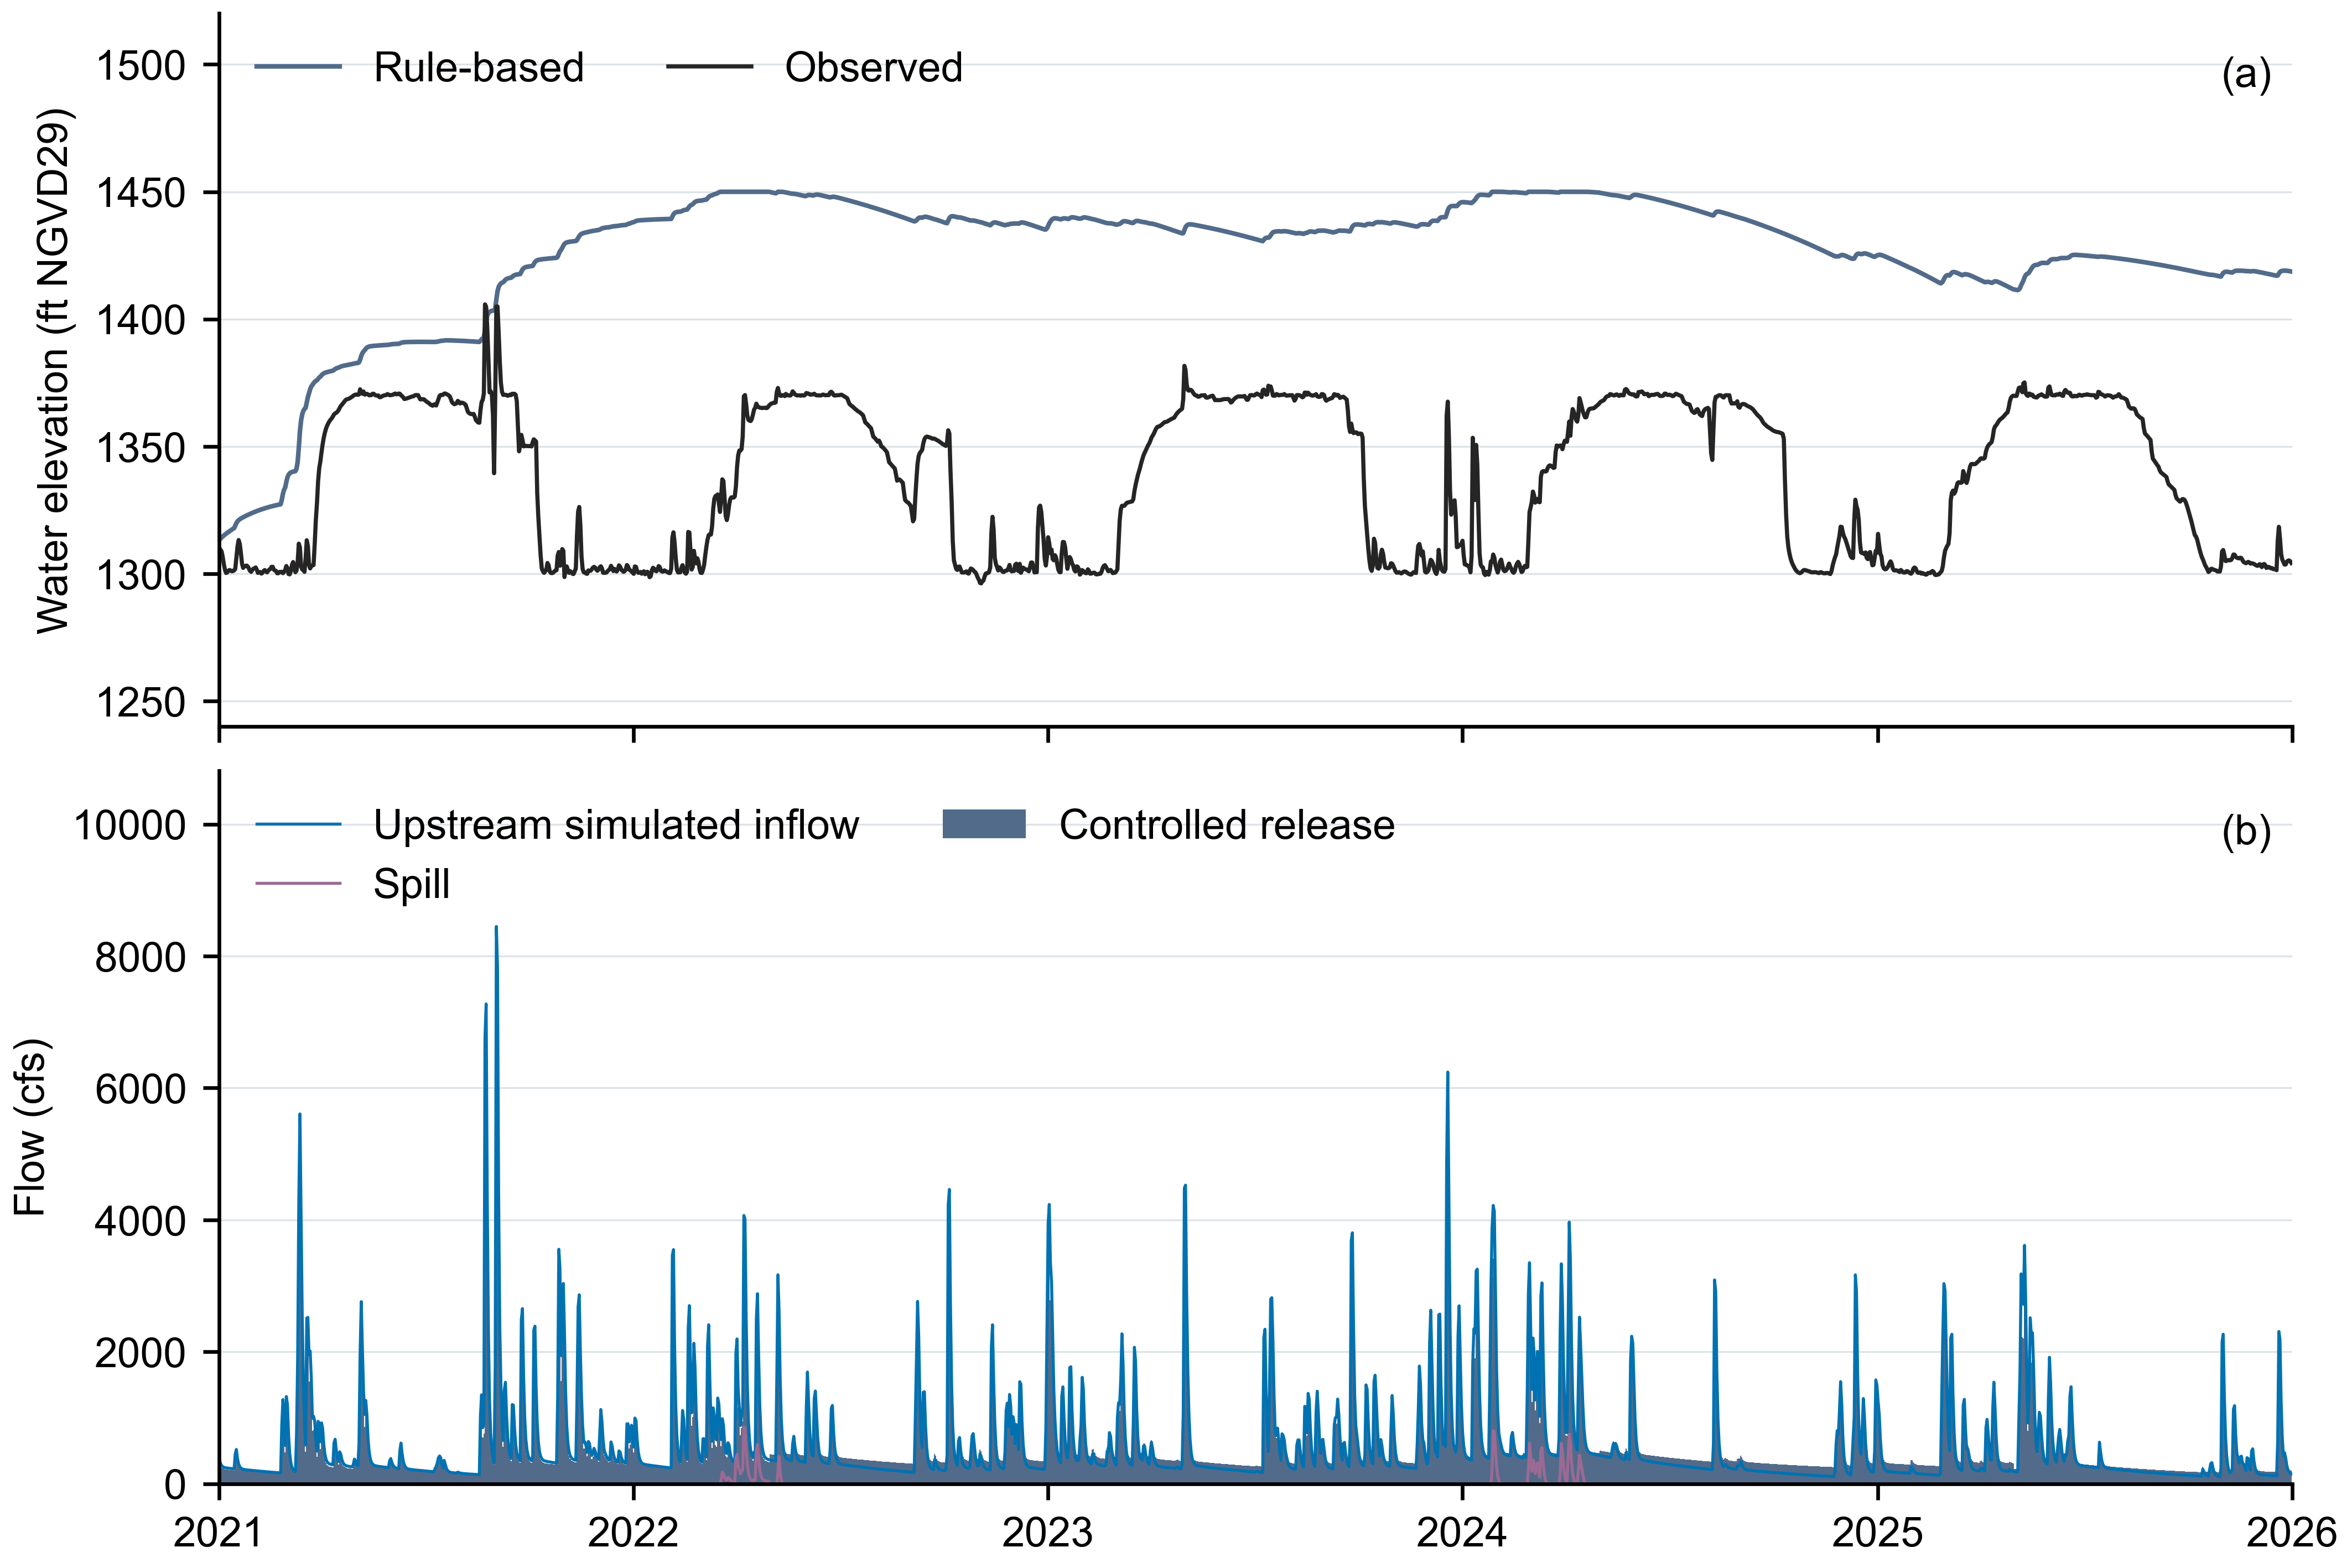

In [8]:
display(Image(filename=str(operation / "outputs/reservoir_operations.png"), width=900))

*Saved Rule-based reservoir evidence, 2021–2025. The upper panel compares
simulated and observed water elevation; the lower panel separates controlled
release, upstream simulated inflow, and spill.*

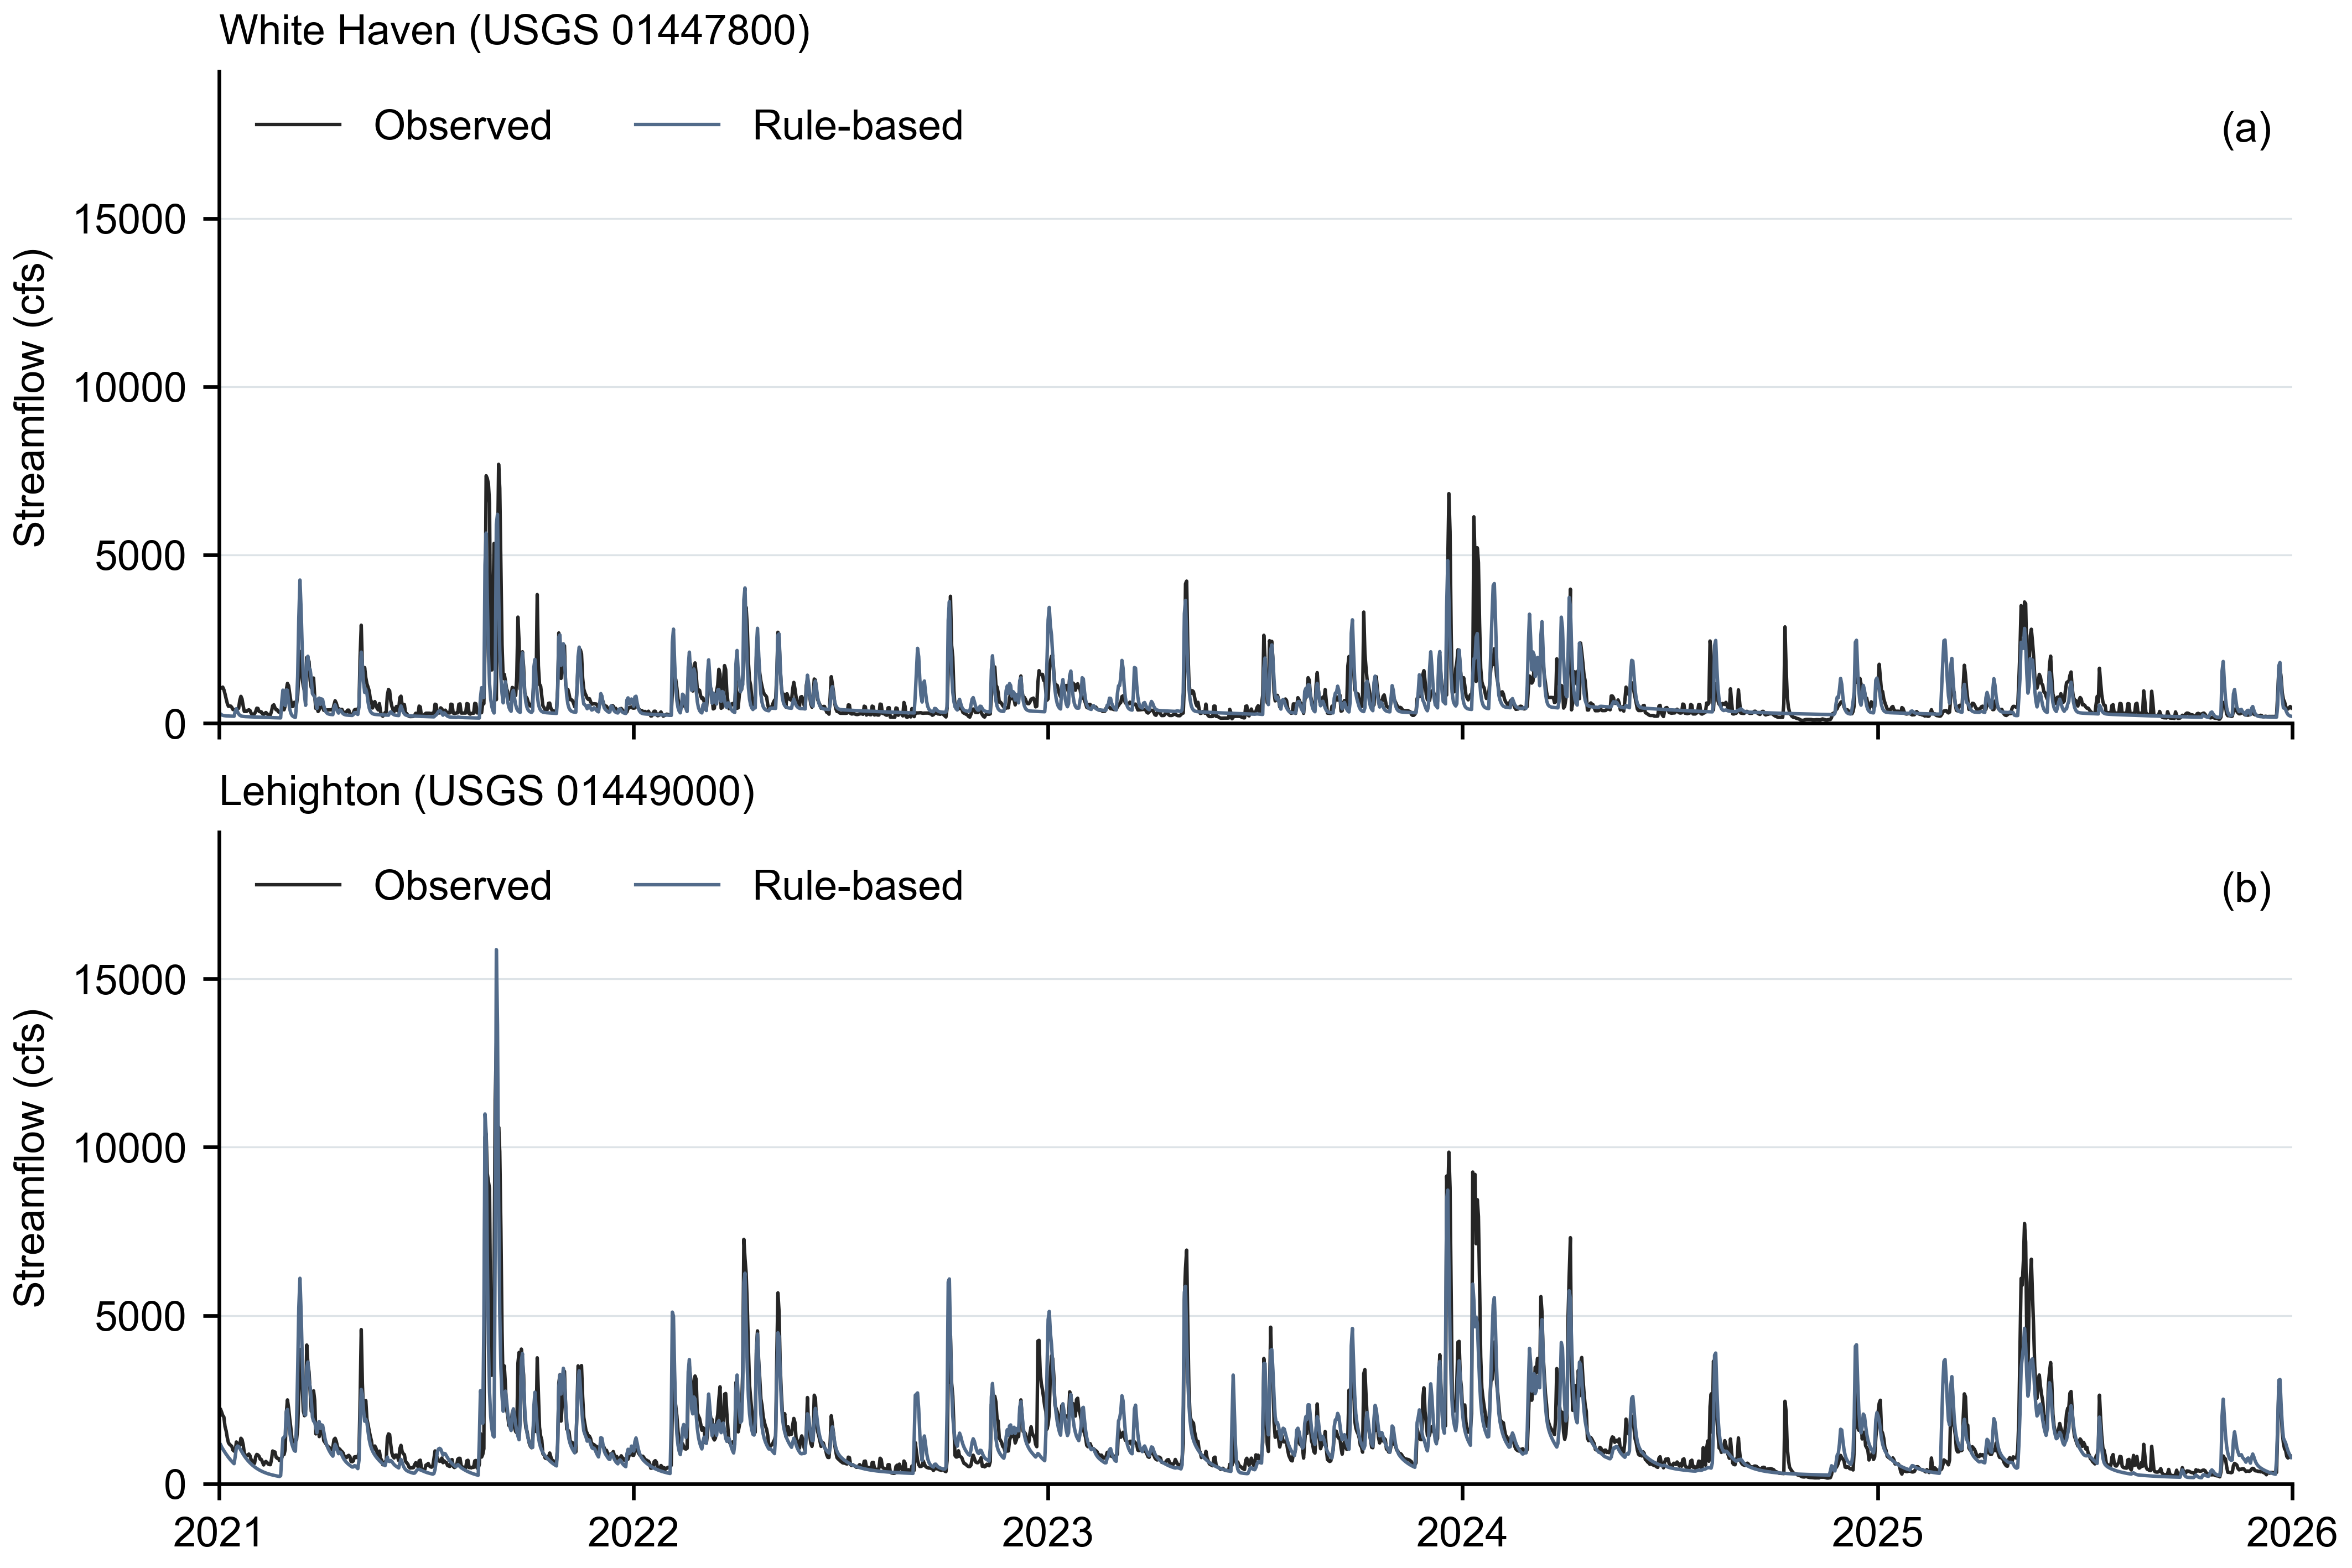

In [9]:
display(Image(filename=str(operation / "outputs/downstream_streamflow.png"), width=900))

*Saved downstream daily mean streamflow at White Haven and Lehighton.
Observation gaps remain gaps; quality masks affect scores rather than plotted dates.*

The non-adopted alpha candidate reduced water-elevation MAE from 88.61 ft
to 57.75 ft, but worsened downstream flow scores and requested unavailable water
on 329 days. The fixed comparison therefore retains `alpha: 0.85` and labels the
candidate as sensitivity evidence.

## Next steps

- Download the [saved baseline files and figures](../examples/fe_walter/operation/README.md).
- Treat the Rule-based series as a generic comparator, not a calibrated optimum.
- Read the [completed hydrology C&V](../examples/fe_walter/downstream/validation.md)
  and retain its observed-boundary scope when interpreting operation differences.
- When LLM runs are eventually authorized and completed, compare them against these
  same inputs and masks; do not substitute the historical 2016 curves.